# *Trabalho Individual – Jogo Quarto*
## Introdução à Inteligência Artificial (2026-27)
### Data limite de entrega 11/11/2026 ás 23:59

---

## O jogo Quarto

O [Quarto](https://en.wikipedia.org/wiki/Quarto_(board_game)) foi concebido por Blaise Muller em 1991. É um jogo abstrato de alinhamento jogado num tabuleiro 4x4 com 16 peças únicas.

Cada peça possui 4 características binárias:
* **Altura:** Alta ou Baixa (`1` ou `0`)
* **Cor:** Clara ou Escura (`1` ou `0`)
* **Forma:** Quadrada ou Redonda (`1` ou `0`)
* **Topo:** Plano ou Côncavo (`1` ou `0`)

A grande particularidade do jogo é que **o jogador não escolhe a peça que vai jogar**: é o adversário que escolhe a peça a ser colocada no tabuleiro no turno do jogador.

Vence quem conseguir alinhar 4 peças com pelo menos uma característica comum na horizontal, vertical ou diagonal.

---

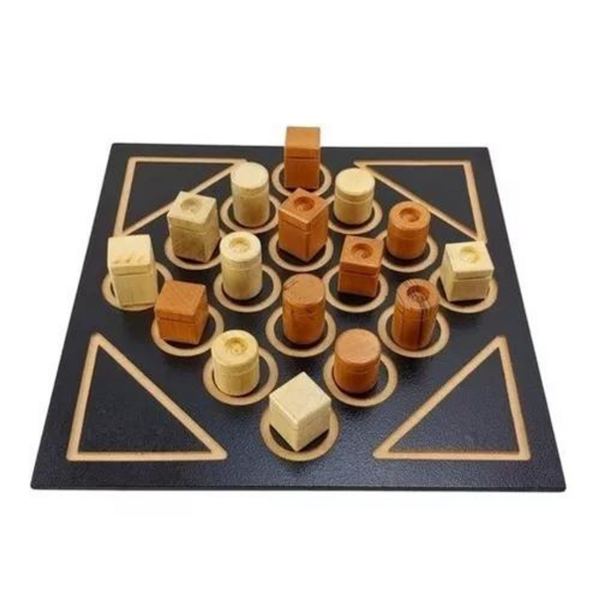

### Como funciona o jogo?

#### 1. Início do Jogo
O tabuleiro consiste numa grelha de 4x4 casas vazias. As 16 peças começam fora do tabuleiro na reserva comum.
* Os jogadores são identificados por `'PLAYER1'` e `'PLAYER2'`.
* O `'PLAYER1'` começa por escolher uma das 16 peças e entrega-a ao `'PLAYER2'`.

#### 2. Jogada e Limite de Tempo (*Timeout*)
Em cada turno, o jogador cuja vez é de jogar tem de realizar **duas decisões consecutivas** na mesma jogada:
1. **Colocar a peça:** Posicionar a peça recebida do adversário numa casa vaga do tabuleiro.
2. **Escolher a peça para o oponente:** Selecionar uma das peças restantes na reserva e entregá-la ao adversário.

⏱️ **Regra do Timeout:**
* O tempo máximo permitido para a execução completa de uma jogada (colocar a peça + escolher a peça seguinte) é definido pela constante da classe **`JogoQuarto.MOVE_TIMEOUT = 0.5s`** (Tempo de calculo da função fibonacci(35)).
* Se o jogador exceder este tempo limite para calcular a sua jogada, é **imediatamente desclassificado**, resultando na **derrota automática** (0 pontos na partida).

#### 3. Fim do Jogo
O jogo termina quando:
* Um jogador coloca uma peça que completa uma linha, coluna ou diagonal de 4 peças com **pelo menos uma característica comum** (ex.: 4 peças altas, 4 peças escuras, etc.). O jogador que colocou essa peça é o **vencedor**.
* Todas as 16 casas são preenchidas sem que nenhum jogador forme um alinhamento válido de 4 peças, resultando em **empate**.
* Um jogador é desclassificado por ultrapassar o tempo limite de jogada (`MOVE_TIMEOUT`).

#### 4. Algumas notas acerca da complexidade
O jogo pode parecer simples, mas tem um espaço de estados bastante vasto.

* **Branching Factor (Fator de Ramificação):**
  * $N_0$ (Escolha inicial de P1): $16$ escolhas de peças
  * $N_1$ (1.ª jogada de P2): $16 \text{ casas} \times 15 \text{ peças} = \mathbf{240}$
  * ...
  * $N_8$ (7.ª jogada de P1): $9 \text{ casas} \times 8 \text{ peças} = \mathbf{72}$
  * ...
  * $N_{16}$ (Última jogada de P1): $1 \text{ casa} = \mathbf{1}$
* **Memória Requerida:**
  * Assumindo que um objeto `EstadoQuarto` simples em Python ocupa entre ~500 bytes a 1 KB em RAM.
  * Supondo que gostaríamos de usar BFS e considerando o acumulado dos estados a guardar na fronteira:
    * Teríamos em $N_8 \approx 29,92 \times 10^{15}$ estados.
    * Isto implicaria uma $\text{Memória Total} \approx 14.96 a 29,92 \times 10^{15} \text{ bytes}$, ou seja, cerca de 30 milhões de Terabytes (assumindo 1Kb por estado).

    (*) Tempo de calculo da função fibonacci(35).
---

## Objetivos do trabalho

Pretende-se que, dada a formulação e implementação do jogo, cada aluno individualmente:

Crie um jogador, sob a forma de uma função de avaliação a ser usada pelo algoritmo alfabeta para qualquer profundidade, par ou ímpar. Aconselha-se o desenvolvimento inicial de um jogador simples para depois ser progressivamente melhorado. Desenvolva e compare o desempenho da sua função de avaliação para diferentes limites de profundidade contra os jogadores de teste fornecidos. Cada aluno submeterá apenas **uma** função de avaliação final.

Em vez de um campeonato entre alunos, a avaliação será feita confrontando a função de avaliação do aluno com três jogadores artificiais com diferentes níveis de dificuldade:

1. ***Novicius*** (Fácil): Um jogador simples que joga maioritariamente com componente aleatória, mas deteta vitórias e derrotas imediatas a 1 jogada de distância.
2. ***Basicus*** (Médio): O jogador de referência (*baseline*). Reconhece vitórias e derrotas imediatas e maximiza o número de alinhamentos de 3 peças com características comuns.
3. ***Optimus*** (Difícil): Um jogador avançado com uma função de avaliação heurística mais sofisticada, que analisa interseções de ameaças e controlo de peças críticas na reserva.
4. ***Minerva*** (Insano) : Mas não é invensível.

O desempenho contra o **Basicus** representa a linha de corte para a nota positiva (10 valores).

---

## Formulação do Jogo Quarto em Python

A modelação do jogo está estruturada através das classes `EstadoQuarto` e `JogoQuarto` no ficheiro `quarto.py`.

In [ ]:
from quarto import JogoQuarto, EstadoQuarto
from jogos import *
from novicius import jogador_novicius

# Inicializar o jogo Quarto
jogo = JogoQuarto()
print("Timeout definido por jogada:", jogo.MOVE_TIMEOUT, "segundo(s)")
print("Estado inicial criado com sucesso!")

### O jogador de referência (Alumnus)
A função de avaliação do jogador ***Alumnus***, `func_alumnus`, serve de base e estrutura para o desenvolvimento do vosso trabalho:

In [ ]:
from jogos import infinity

def func_alumnus(estado, jogador):
    #TODO
    return 0


def jogador_alumnus(jogo, estado):
    return alphabeta_cutoff_search_new(estado, jogo, d=1, eval_fn=func_alumnus)

### Exemplo de Partida de Teste

Este script python permite visualizar o decorrer de uma partida e o resultado

In [ ]:
# Partida de teste entre o Alumnus e o Random com controlo de tempo automático
jogo = JogoQuarto()
resultado = jogo.jogar(jogador_alumnus, jogador_novicius, verbose=True)
print("Utilidade da partida para o "+jogo.nome_player1.upper()+":", resultado, f"( {((resultado +1)/2):1} pts)")

--- 
## Material a entregar
Cada aluno deve submeter um único ficheiro com o seu número de aluno: **Quarto_proj_alunoXXXXX.py** (onde XXXXX é o número de aluno).

<span style="color:red"> **Não altere**</span> `quarto.py`, `utils.py` e `jogos_melhor.py` e **não os submeta!**
<br><span style="color:red">**Não redefina**</span> funções com o mesmo nome das já existentes nestes ficheiros.

A função de avaliação do aluno deverá ter a assinatura **`func_alumnus(estado, jogador)`** (substituindo XXXXX pelo número de aluno) e deve devolver o valor estimado do `estado` na perspetiva do `jogador`.

A função que usa a a **func_alumnus** e invoca o algoritmo alphabeta para realizar a procura nos espaço de estados deverá ter assinatura **jogador_alumnus(jogo, estado)**. Tenha atenção à escolha do parametro de limite de profundidade do algoritmo alphabeta.

**Todas** as outras funções auxiliares criadas devem ter o sufixo **_XXXXX** (com o número de aluno).

--- 
## Avaliação

A avaliação será realizada através de um conjunto de partidas diretas entre o jogador desenvolvido pelo aluno e os 4 jogadores artificiais (*Novicius*, *Basicus*, *Optimus*, *Minerva*), jogando em ambas as posições (como 1.º jogador e como 2.º jogador).

* **Pontuação por partida:**
  * Vitória: 1 pontos
  * Empate: 0.5 ponto
  * Derrota / Timeout: 0 pontos

* **Cálculo da Nota:**
  * ** A nota será dado pela soma de pontos obtidos no confronto com os vários jogadores

**Plágio e Cópias:** A submissão de código idêntico ao de jogadores de outros alunos resultará na anulação da prova (0 valores).

**Timeout:** Se um jogador exceder o tempo limite de `MOVE_TIMEOUT` segundos numa jogada durante os testes automáticos, a partida será interrompida e considerada como derrota.

**NOTA:** Como o hardware não é homogéneo, os tempos de processamento podem variar. De modo a reduzir esta variância em tempos, o timeout vai ser definido como o tempo em que é calculada a sequência de fibonacci(35).